### 案例2 新闻多分类

In [115]:
import random
import numpy as np
import pandas as pd

# 划分训练集与测试集
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset # 数据集组织，以便后面batch划分
import torch.optim as optim # 优化器

In [116]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker  # 导入刻度格式化模块
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC']  # 支持中文字体
plt.rcParams['figure.dpi'] = 300   # Notebook 中显示的清晰度
plt.rcParams['savefig.dpi'] = 300  # 保存图片的清晰度
plt.rcParams['font.size'] = 12

In [117]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"正在使用的设备: {device}")

正在使用的设备: cuda


In [118]:
# 设置随机种子（不含对batch划分的设置）
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)                # PyTorch CPU随机数
    torch.cuda.manual_seed(seed)           # PyTorch 当前GPU随机数
    torch.cuda.manual_seed_all(seed)       # PyTorch 所有GPU随机数
    torch.backends.cudnn.deterministic = True # 强制CuDNN使用确定性算法
    torch.backends.cudnn.benchmark = False # 关闭CuDNN的自动寻找最优算法

set_seed(42)

In [119]:
# 导入数据，并观察数据形状
from keras.datasets import reuters
(x_train, y_train), (x_test, y_test) = reuters.load_data(num_words=10000)

print(f"训练集特征形状: {x_train.shape}")
print(f"训练集标签形状: {y_train.shape}")
print(f"测试集特征形状: {x_test.shape}")
print(f"测试集标签形状: {y_test.shape}")

训练集特征形状: (8982,)
训练集标签形状: (8982,)
测试集特征形状: (2246,)
测试集标签形状: (2246,)


In [120]:
print(x_train[0])
print(y_train[0])

[1, 2, 2, 8, 43, 10, 447, 5, 25, 207, 270, 5, 3095, 111, 16, 369, 186, 90, 67, 7, 89, 5, 19, 102, 6, 19, 124, 15, 90, 67, 84, 22, 482, 26, 7, 48, 4, 49, 8, 864, 39, 209, 154, 6, 151, 6, 83, 11, 15, 22, 155, 11, 15, 7, 48, 9, 4579, 1005, 504, 6, 258, 6, 272, 11, 15, 22, 134, 44, 11, 15, 16, 8, 197, 1245, 90, 67, 52, 29, 209, 30, 32, 132, 6, 109, 15, 17, 12]
3


In [121]:
# one-hot编码：针对10000个高频词，将每条评论数据，转换为10000个元素的序列
def vectorize_sequences(sequences, dimension=10000):   
    results = np.zeros((len(sequences), dimension)) # 形状：(len(str_val), 10000)
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.
    return results

x_train = vectorize_sequences(x_train) 
x_test = vectorize_sequences(x_test)

# 在PyTorch框架下，不需要针对 无序多分类标签 进行one-hot化

In [122]:
# 划分训练集与测试集为80%:20%
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, 
    train_size=0.8, 
    test_size=0.2, 
    random_state=42
)

In [123]:
# 将特征、标签等数据，转换为torch中的张量
x_train_tensor = torch.tensor(x_train, dtype = torch.float32)
x_val_tensor = torch.tensor(x_val, dtype = torch.float32)
x_test_tensor = torch.tensor(x_test, dtype = torch.float32)

y_train_tensor = torch.tensor(y_train, dtype = torch.long) # 无序类别标签，类型必须是torch.long
y_val_tensor = torch.tensor(y_val, dtype = torch.long)
y_test_tensor = torch.tensor(y_test, dtype = torch.long)

In [124]:
# 自定义网络结构
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(10000, 64) # 输入层 10000 -> 隐藏层1 64
        self.fc2 = nn.Linear(64, 64) # 隐藏层1 64 -> 隐藏层2 64
        self.out = nn.Linear(64, 46) # 隐藏层2 64 -> 输出层 46
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.out(x)  # 输出线性结果
        return x

In [125]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

In [126]:
# 训练模型，并在每轮epoch后，针对训练数据评估模型
def train_and_val_model(model, epochs, batch):
    # 将模型迁移到GPU训练
    model = model.to(device)

    # 全数据集分batch
    g = torch.Generator()
    g.manual_seed(42) # 为了可复现，为batch划分也设置固定随机种子
    
    train_dataset = TensorDataset(x_train_tensor, y_train_tensor) # 特征与标签，一起构造成torch张量数据集
    train_dataloader = DataLoader(train_dataset, batch_size=batch, shuffle=True, generator=g) # 将数据集组织成 以batch加载 的形式

    loss_result = []
    for epoch in range(epochs):
        train_total_loss_sum = 0.0  # 记录每个epoch的总损失
        train_num = 0   # 记录训练集的总样本数
        train_correct = 0   # 计算train的每一epoch的正确样本数

        model.train()  # 设置为训练模式
        for batch_x, batch_y in train_dataloader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            preds_y = model(batch_x) # 前向传播
                      
            predicted_classes = torch.argmax(preds_y, dim=1) # 将概率最大的标签值，作为预测结果 
            # 统计预测正确的样本数
            train_correct += (predicted_classes == batch_y).sum().item() 

            loss_train = criterion(preds_y, batch_y) # 计算损失
            optimizer.zero_grad() # 梯度清零
            loss_train.backward() # 反向传播（自动求导 并 累加梯度）
            optimizer.step() # 根据求导计算出的 梯度，更新模型参数

            # 为便于最后计算总平均loss，通过乘以batch样本数，加和单batch下的loss总和
            train_total_loss_sum += loss_train.item() * batch_y.size(0) 
            train_num += batch_y.size(0)

        # 计算train的Loss与Acc
        train_loss = train_total_loss_sum / train_num
        train_acc = train_correct / train_num

        # 设置为评估模式
        model.eval() 
        val_dataset = TensorDataset(x_val_tensor, y_val_tensor) 
        val_dataloader = DataLoader(val_dataset, batch_size=batch, shuffle=True, generator=g) 
        val_total_loss_sum = 0.0  # 记录每个epoch的总损失
        val_num = 0   # 记录验证集的总样本数
        val_correct = 0   # 验证集正确样本数
        
        with torch.no_grad(): # 关闭梯度计算，节省内存
            for batch_x, batch_y in val_dataloader:
                batch_x = batch_x.to(device)
                batch_y = batch_y.to(device)
                
                val_preds = model(batch_x) # 前向传播
          
                val_predicted_classes = torch.argmax(val_preds, dim=1) # 将概率最大的标签值，作为预测结果 
                val_correct += (val_predicted_classes == batch_y).sum().item() # 统计预测正确的样本数
                val_num += batch_y.size(0)

                val_total_loss_sum = criterion(val_preds, batch_y).item() * batch_y.size(0)

        # 计算val的Loss与Acc
        val_loss = val_total_loss_sum / val_num
        val_acc = val_correct / val_num
        
        loss_result.append([f"{epoch + 1}/{epochs}", 
                            train_loss, 
                            train_acc,
                            val_loss,
                            val_acc
                        ]) # 记录每epoch的loss与Acc
        # print(f"训练进度: {epoch+1}/{epochs}, 训练集loss: {train_total_loss_sum / train_num:.4f}, 训练集Acc: {train_correct / train_num * 100:.2f}%  ({train_correct}/{train_num})")

    result_df = pd.DataFrame(loss_result, columns=['Epoch', 'Train_Loss', 'Train_Acc', 'Val_Loss', 'Val_Acc'])
    return result_df

In [127]:
train_result_df = train_and_val_model(model, epochs=20, batch = 512)
train_result_df.style.format({'Train_Acc': '{:.2%}', 'Val_Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Train_Loss,Train_Acc,Val_Loss,Val_Acc
1/20,2.261749,50.35%,0.229755,66.44%
2/20,1.246836,71.69%,0.178108,71.29%
3/20,0.943579,79.11%,0.163886,74.01%
4/20,0.732127,84.01%,0.148344,76.79%
5/20,0.579679,87.25%,0.162993,76.74%
6/20,0.468778,89.73%,0.154261,75.18%
7/20,0.391475,91.57%,0.105225,77.74%
8/20,0.322207,93.00%,0.182531,68.89%
9/20,0.290962,93.42%,0.119373,81.52%
10/20,0.238439,94.71%,0.114748,80.58%


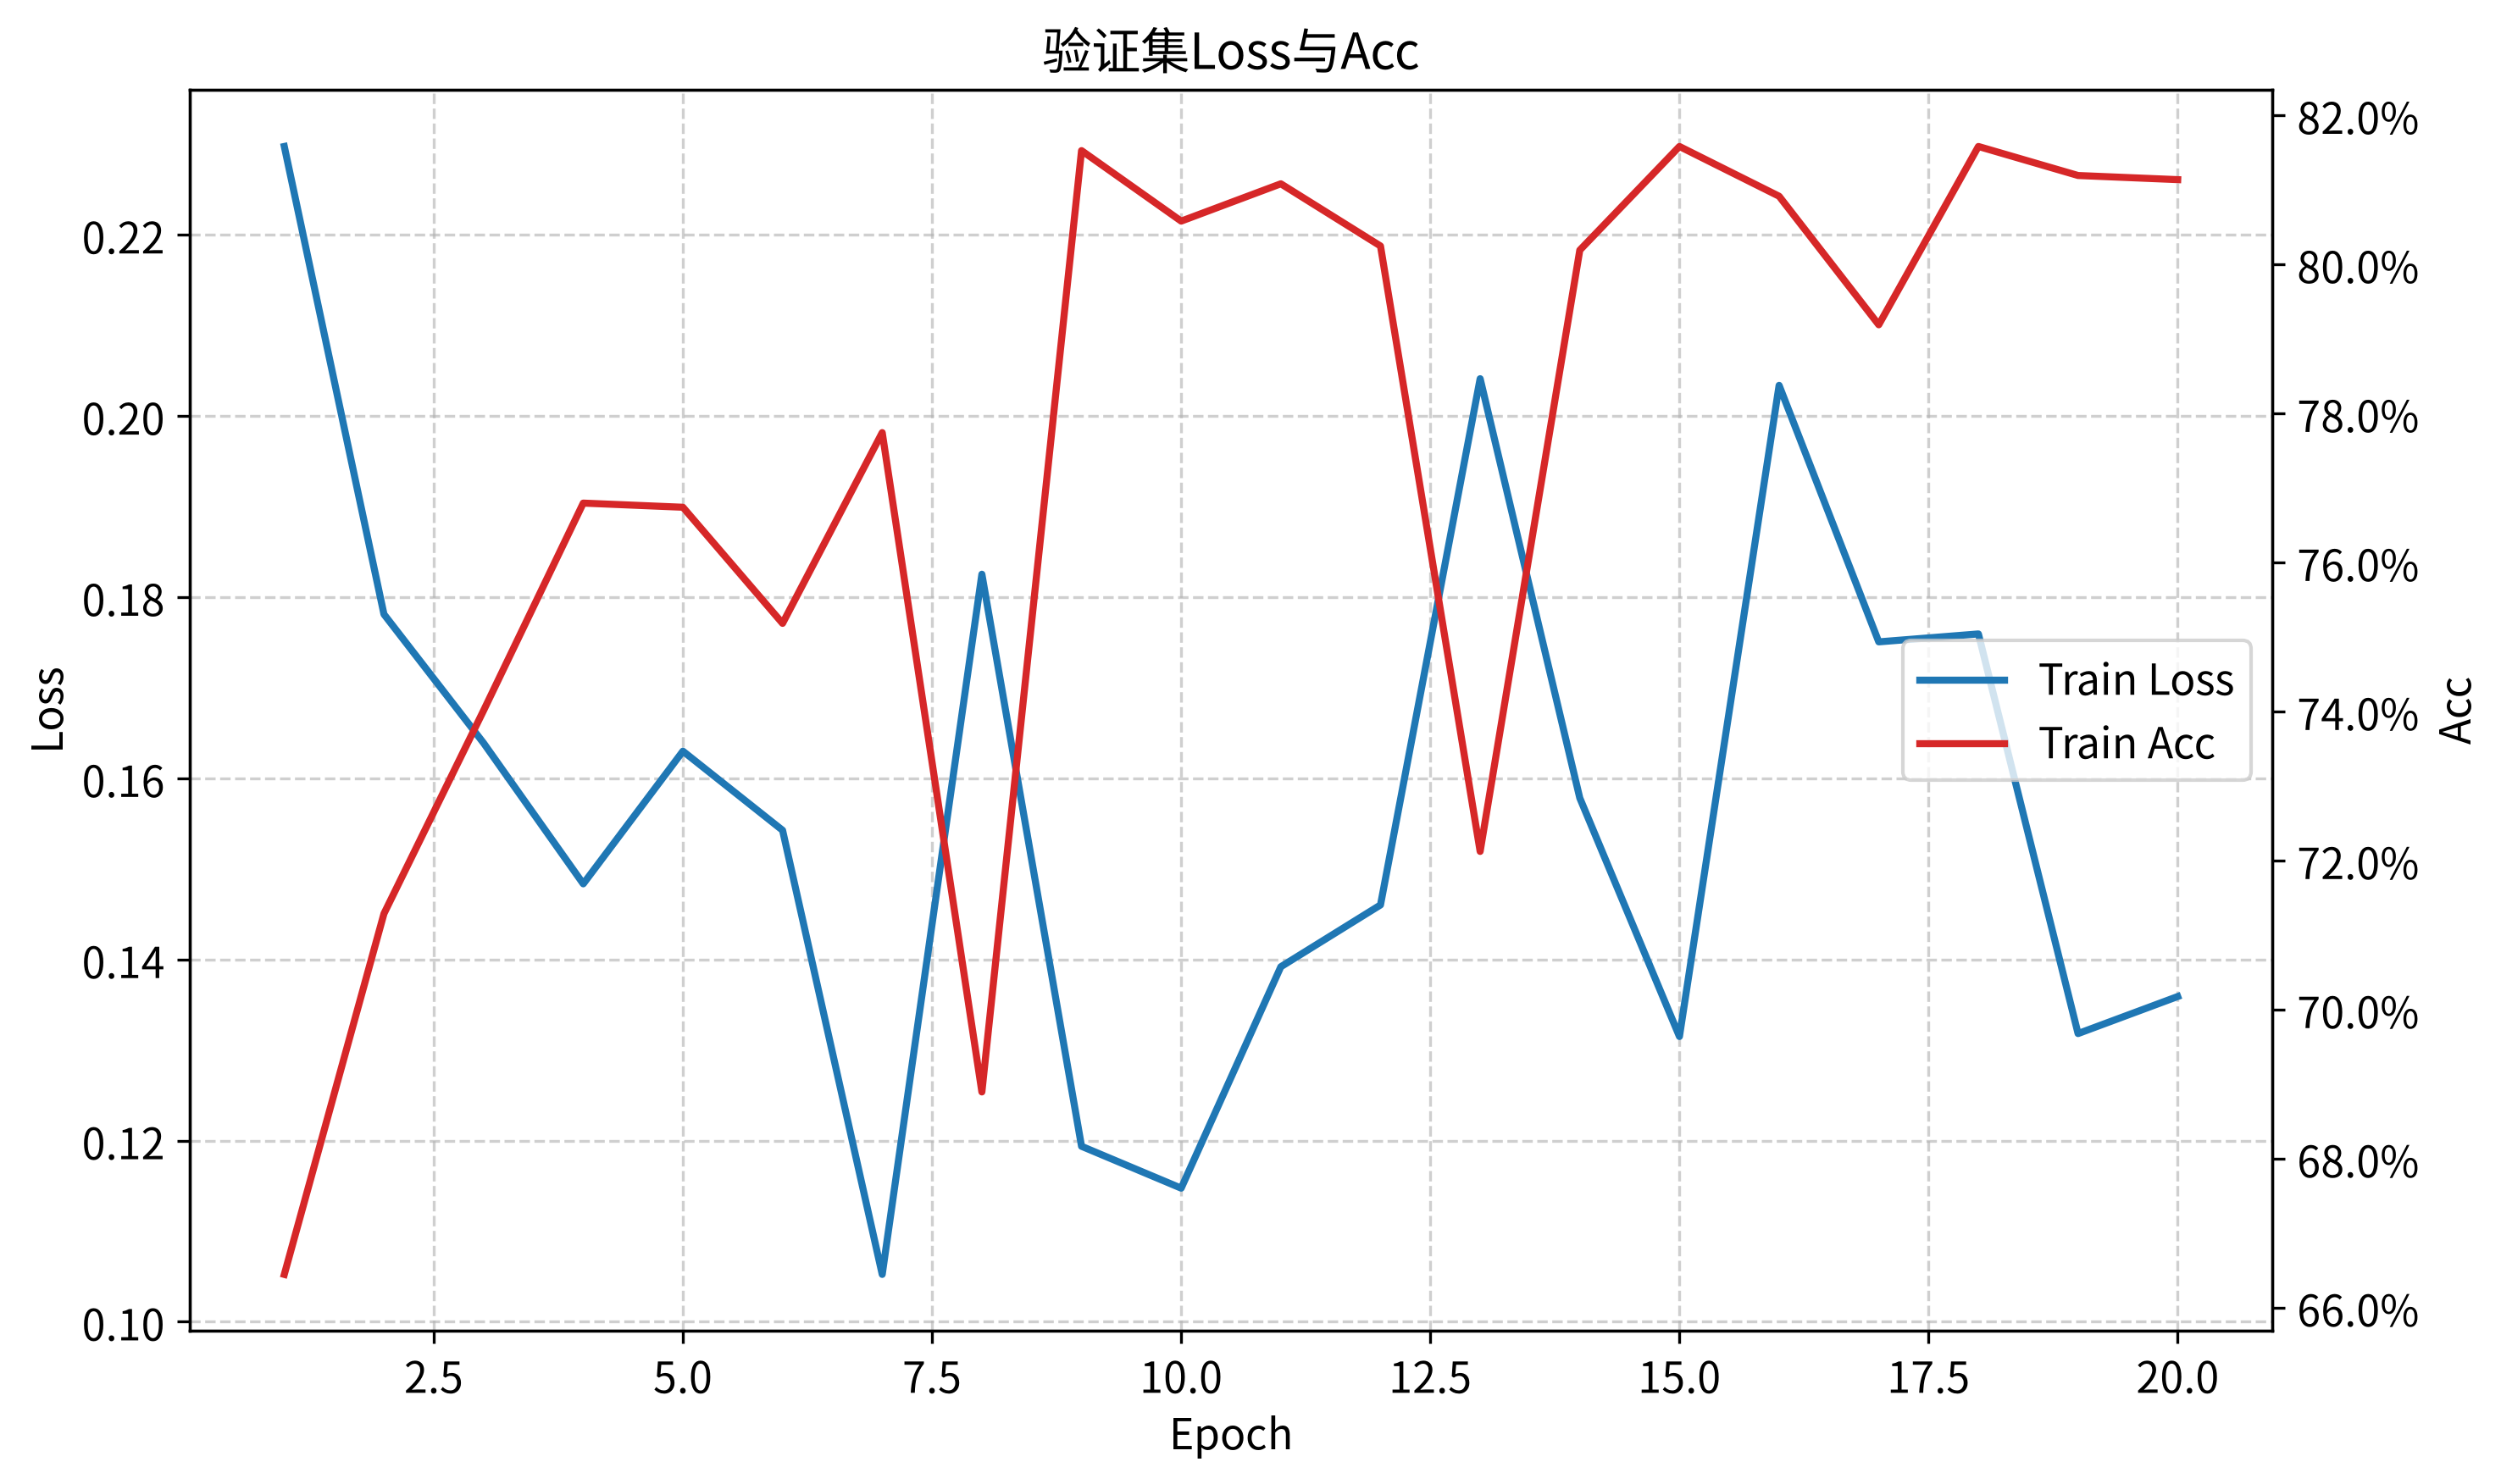

In [128]:
# 从结果列表中提取 loss 和 acc 数据
losses = train_result_df['Val_Loss']
accs = train_result_df['Val_Acc']
epochs = range(1, len(losses) + 1)

# 初始化画布
fig, ax1 = plt.subplots(figsize=(10, 6)) # ax1 作为左侧主坐标轴

# 绘制左侧Loss（蓝线）
color_loss = 'tab:blue'
line1 = ax1.plot(epochs, losses, label='Train Loss', color=color_loss, linewidth=2)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.tick_params(axis='y') # 刻度线颜色与线条一致
ax1.grid(True, linestyle='--', alpha=0.6) # 加网格

# 绘制右侧Acc（红线）
ax2 = ax1.twinx()  
color_acc = 'tab:red'
line2 = ax2.plot(epochs, accs, label='Train Acc', color=color_acc, linewidth=2)
ax2.set_ylabel('Acc', fontsize=12)
ax2.tick_params(axis='y')

ax2.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0, decimals=1)) # 将Acc轴格式化为百分比

# 合并图例
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right', fontsize=12)

# 设置标题并显示
plt.title('验证集Loss与Acc', fontsize=14)
plt.tight_layout()
plt.show()

In [129]:
# 在测试集上评估模型并预测
def evaluate_model(model, batch):
    model.eval() # 将模型切换到测试状态
    test_correct = 0
    test_num = 0
    test_total_loss_sum = 0.0

    test_result = []

    # 同样分batch进行测试
    test_dataset = TensorDataset(x_test_tensor, y_test_tensor)
    test_dataloader = DataLoader(test_dataset, batch_size=batch, shuffle=False)

    with torch.no_grad(): # 关闭梯度计算，节省内存
        for batch_x, batch_y in test_dataloader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)
                
            test_preds = model(batch_x) # 前向传播
          
            test_predicted_classes = torch.argmax(test_preds, dim=1) # 将概率最大的标签值，作为预测结果 
            test_correct += (test_predicted_classes == batch_y).sum().item() # 统计预测正确的样本数
            test_num += batch_y.size(0)

            test_result += test_predicted_classes.tolist()
            test_total_loss_sum = criterion(test_preds, batch_y).item() * batch_y.size(0)

    avg_test_loss = test_total_loss_sum / test_num  # 计算总平均loss
    accuracy = test_correct / test_num    # 计算Acc

    print(f"测试集loss: {avg_test_loss:.4f}")
    print(f"测试集Acc: {accuracy * 100:.2f}%  ({test_correct}/{test_num})")

    # 预测结果
    result_df = pd.DataFrame(test_result, columns=['Predict'])
    
    return result_df

In [130]:
test_result = evaluate_model(model, batch=128)
test_result.round(4)

测试集loss: 0.0488
测试集Acc: 78.67%  (1767/2246)


,Predict
0,3
1,28
2,1
3,4
4,13
...,...
2241,3
2242,3
2243,3
2244,3
